# Sentiment Classification for Yoruba Tweets
Project presentation notebook

Everything below loads results saved from my main notebook, nothing is retrained here.

## 1. Problem and data
Three-class sentiment on Yoruba tweets: positive, neutral, negative.

In [37]:
# Imports for the whole presentation notebook
import os
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score
from gradio_client import Client

import re
import unicodedata
from huggingface_hub import hf_hub_download, list_repo_files
import logging
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 160)

,Tweets
Train,"8,522"
Validation,"2,090"
Test,"4,515"


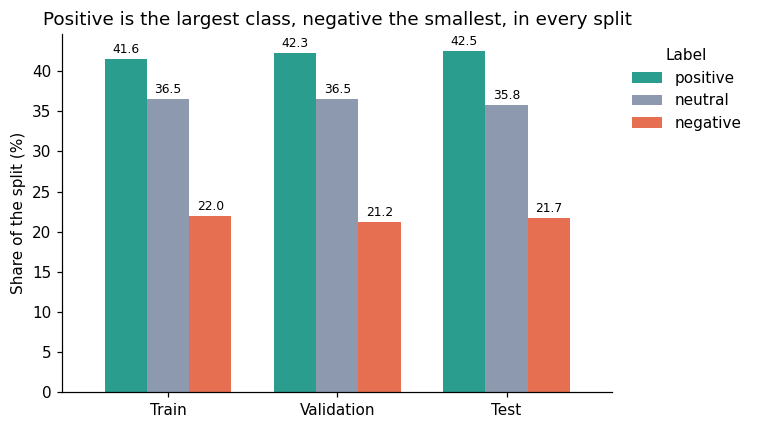

Label,Example tweet
positive,"Músò! Músò! Músò! Ọmọ ikọ̀ #RealMadrid, ẹ kú oríre o. Ó yá músò, músò, músò ... #idanoripapa"
positive,Ekaáro eyin eyan mi gbogbo #TweetinYoruba
neutral,"Wọ́n á ní Ògbómọ̀ṣọ́ Ajílété. Ẹ jọ̀wọ́ kí ni ìtumọ̀ ajílété o, ẹ̀yin ọmọ Ògbómọ̀ṣọ́? @user"
neutral,#DidYouKnow ju awọn ọmọ Afirika 5 000 000 lọ lori Twitter. Ọpọlọpọ wa lati awọn orilẹ-ede wọnyi: ZA 🇿🇦 NG 🇳🇬 KE 🇰🇪 ET 🇪🇹 TZ 🇹🇿 ZIM 🇿🇼 nibi ti ọpọlọpọ awọn ede Afirika ti awọn ori oke10 wa lati. Ṣe o mọ eyi? #Yoruba #AfricanLanguagesDay #IsComingSoon https://t.co/atUqRyw2om
negative,"#iroyin, #yoruba, Bamigboye fo igo mo Segun lori, lo ba foju bale ejo: Tolulope Emmanuel… https://t.co/qYNBC1V743"
negative,AWORON: LAMIDO SANUSI dojuti Aaare Jonathan. O gun Esin Iwuye wo afin lati di Emir ilu Kano http://t.co/re2ZFJTTl3


In [8]:
# [1] Splits, class balance and example tweets
LABELS = {0: "positive", 1: "neutral", 2: "negative"}
ORDER = ["positive", "neutral", "negative"]

splits = {s: pd.read_parquet(f"{CKPT_DIR}/step1_raw_{s}.parquet") for s in ["train", "validation", "test"]}
for s, d in splits.items():
    d["label_name"] = d["label"].map(LABELS)

sizes = pd.DataFrame({"Tweets": {s.capitalize(): f"{len(d):,}" for s, d in splits.items()}})
display(sizes)

share = pd.DataFrame({s.capitalize(): d["label_name"].value_counts(normalize=True).mul(100).reindex(ORDER)
                      for s, d in splits.items()})

fig, ax = plt.subplots(figsize=(7, 4))
share.T.plot.bar(ax=ax, rot=0, width=0.75, color=["#2a9d8f", "#8d99ae", "#e76f51"])
ax.set_ylabel("Share of the split (%)")
ax.set_title("Positive is the largest class, negative the smallest, in every split")
ax.legend(title="Label", frameon=False, bbox_to_anchor=(1.01, 1))
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8, padding=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

examples = pd.concat([splits["train"][splits["train"]["label_name"] == n].sample(2, random_state=1)
                      for n in ORDER])[["label_name", "tweet"]]
examples.columns = ["Label", "Example tweet"]
display(examples.reset_index(drop=True).style.hide(axis="index").set_properties(**{"text-align": "left"}))

## 2. Test tweets that were also in training

,Tweets,Seen in training,Unseen,Share seen
Validation,"2,090",306,"1,784",14.6%
Test,"4,515",577,"3,938",12.8%


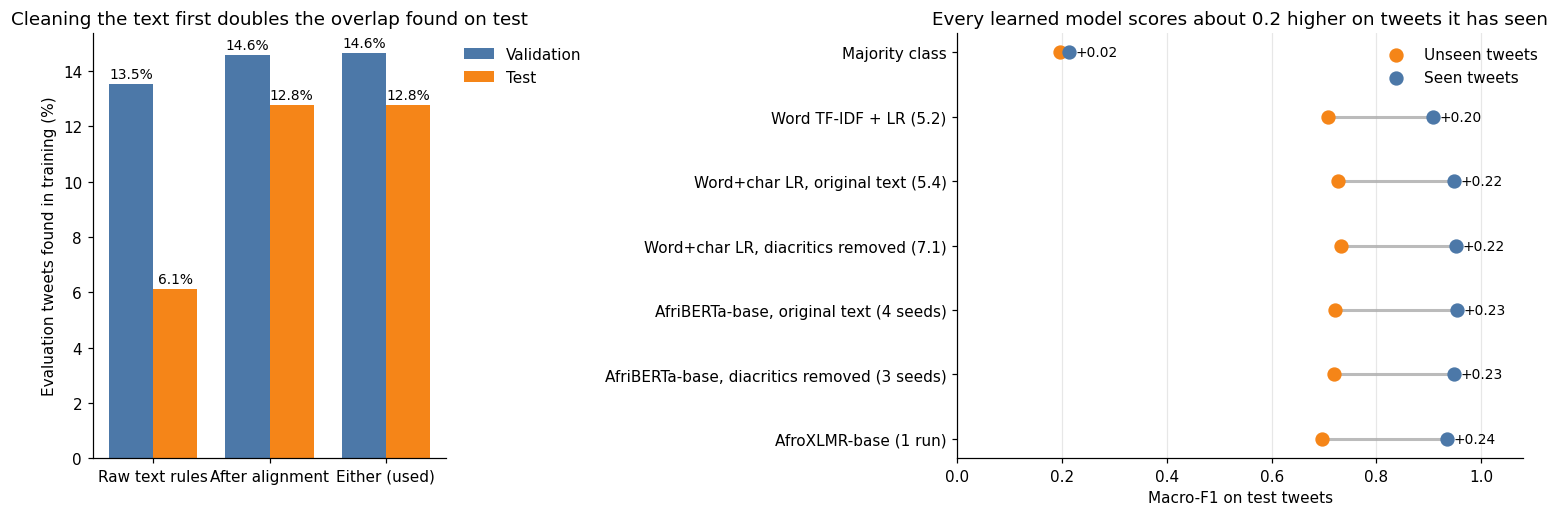

In [24]:
# [2] Overlap between evaluation tweets and the training data, and what it does to the scores
flags = {s: pd.read_parquet(f"{CKPT_DIR}/step4_flags_{s}.parquet") for s in ["validation", "test"]}

table = pd.DataFrame({
    s.capitalize(): {
        "Tweets": f"{len(d):,}",
        "Seen in training": f"{int(d['seen_in_training'].sum()):,}",
        "Unseen": f"{int((~d['seen_in_training']).sum()):,}",
        "Share seen": f"{100 * d['seen_in_training'].mean():.1f}%",
    } for s, d in flags.items()
}).T
display(table)

fc = pd.read_csv(f"{CKPT_DIR}/final_comparison.csv", index_col=0)
unseen = fc["test_unseen macro-F1"]
seen = unseen + fc["memorization gap (seen - unseen)"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})

rules = [("Raw text rules", "seen_v1"), ("After alignment", "seen_aligned"), ("Either (used)", "seen_in_training")]
x = np.arange(len(rules)); w = 0.38
for k, (s, color) in enumerate([("validation", "#4c78a8"), ("test", "#f58518")]):
    vals = [100 * flags[s][c].mean() for _, c in rules]
    bars = ax1.bar(x + (k - 0.5) * w, vals, w, label=s.capitalize(), color=color)
    ax1.bar_label(bars, fmt="%.1f%%", fontsize=9, padding=2)
ax1.set_xticks(x); ax1.set_xticklabels([r[0] for r in rules])
ax1.set_ylabel("Evaluation tweets found in training (%)")
ax1.set_title("Cleaning the text first doubles the overlap found on test")
ax1.legend(frameon=False, bbox_to_anchor=(1.01, 1))

names = list(fc.index)[::-1]
for i, n in enumerate(names):
    ax2.plot([unseen[n], seen[n]], [i, i], color="#bbbbbb", lw=2, zorder=1)
    ax2.text(max(seen[n], unseen[n]) + 0.012, i, f"+{seen[n] - unseen[n]:.2f}", va="center", fontsize=9)
ax2.scatter([unseen[n] for n in names], range(len(names)), color="#f58518", s=70, zorder=2, label="Unseen tweets")
ax2.scatter([seen[n] for n in names], range(len(names)), color="#4c78a8", s=70, zorder=2, label="Seen tweets")
ax2.set_yticks(range(len(names))); ax2.set_yticklabels(names)
ax2.set_xlim(0, 1.08); ax2.set_xlabel("Macro-F1 on test tweets")
ax2.set_title("Every learned model scores about 0.2 higher on tweets it has seen")
ax2.legend(frameon=False , bbox_to_anchor=(1.05, 1))
ax2.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Models and settings

Model,Settings,Size,Role
Majority class,Always predicts the most common training label,None,Floor for every other model
Word TF-IDF + logistic regression,"Words and word pairs, minimum 2 tweets, C = 1, balanced class weights","25,759 features",Simple baseline
Word + character TF-IDF + logistic regression,"Words plus character 2 to 5-grams, C = 3, balanced class weights, chosen from 12 settings on validation","Linear model, 2.6 MB",Deployed main model
"AfriBERTa-base, fine-tuned","Learning rate 5e-5, batch 32, up to 5 epochs, max length 128, AdamW, weighted loss, best epoch on validation",About 111M parameters,Deployed second opinion
"AfroXLMR-base, fine-tuned","Same recipe, learning rate 3e-5 for 5 epochs and 5e-5 for 8 epochs",XLM-R vocabulary,"Compared, not deployed"


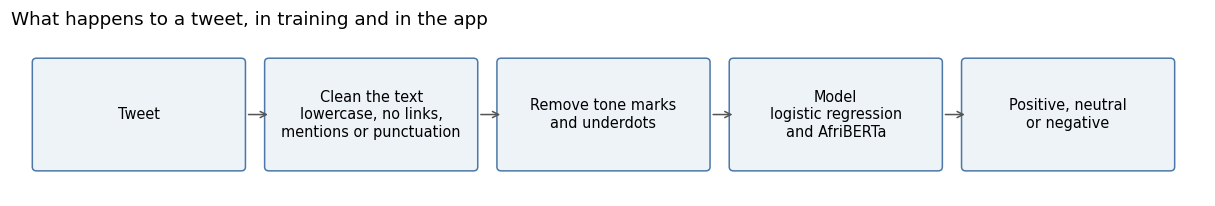

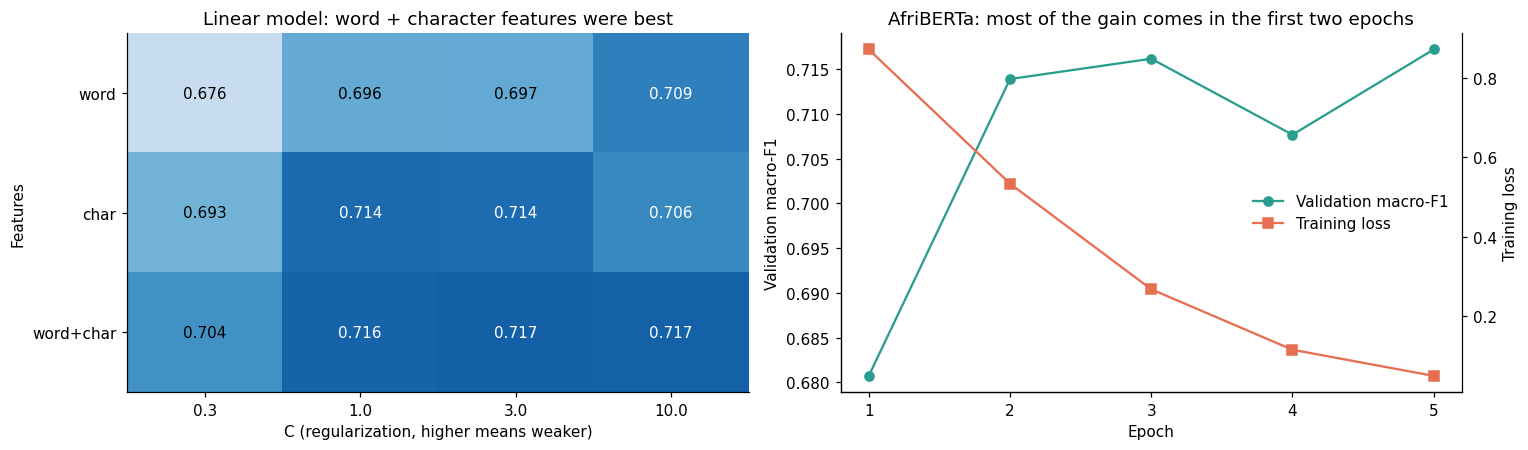

In [26]:
# [3] Models, settings, input pipeline and how the settings were chosen
from matplotlib.patches import FancyBboxPatch

models = pd.DataFrame([
    ["Majority class", "Always predicts the most common training label", "None", "Floor for every other model"],
    ["Word TF-IDF + logistic regression", "Words and word pairs, minimum 2 tweets, C = 1, balanced class weights", "25,759 features", "Simple baseline"],
    ["Word + character TF-IDF + logistic regression", "Words plus character 2 to 5-grams, C = 3, balanced class weights, chosen from 12 settings on validation", "Linear model, 2.6 MB", "Deployed main model"],
    ["AfriBERTa-base, fine-tuned", "Learning rate 5e-5, batch 32, up to 5 epochs, max length 128, AdamW, weighted loss, best epoch on validation", "About 111M parameters", "Deployed second opinion"],
    ["AfroXLMR-base, fine-tuned", "Same recipe, learning rate 3e-5 for 5 epochs and 5e-5 for 8 epochs", "XLM-R vocabulary", "Compared, not deployed"],
], columns=["Model", "Settings", "Size", "Role"])
display(models.style.hide(axis="index").set_properties(**{"text-align": "left"}))
display(HTML("<style>th{text-align:left !important}</style>"))

fig, ax = plt.subplots(figsize=(14, 1.9))
ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 2)
steps = ["Tweet", "Clean the text\nlowercase, no links,\nmentions or punctuation", "Remove tone marks\nand underdots",
         "Model\nlogistic regression\nand AfriBERTa", "Positive, neutral\nor negative"]
xs = np.linspace(0.3, 11.2, len(steps))
for x, s in zip(xs, steps):
    ax.add_patch(FancyBboxPatch((x, 0.35), 2.4, 1.3, boxstyle="round,pad=0.05", fc="#eef3f8", ec="#4c78a8"))
    ax.text(x + 1.2, 1.0, s, ha="center", va="center", fontsize=9.5)
for x in xs[:-1]:
    ax.annotate("", xy=(x + 2.75, 1.0), xytext=(x + 2.45, 1.0), arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_title("What happens to a tweet, in training and in the app", loc="left")
plt.show()

grid = pd.DataFrame(json.load(open(f"{CKPT_DIR}/baseline_grid.json")))
piv = grid.pivot(index="features", columns="C", values="val_unseen_macro_f1").loc[["word", "char", "word+char"]]
hist = pd.DataFrame(json.load(open(f"{CKPT_DIR}/afriberta_run.json"))["history"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax1.imshow(piv.values, cmap="Blues", vmin=0.66, vmax=0.73, aspect="auto")
ax1.set_xticks(range(piv.shape[1])); ax1.set_xticklabels(piv.columns)
ax1.set_yticks(range(piv.shape[0])); ax1.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax1.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=10,
                 color="white" if piv.values[i, j] > 0.705 else "black")
ax1.set_xlabel("C (regularization, higher means weaker)"); ax1.set_ylabel("Features")
ax1.set_title("Linear model: word + character features were best")

ax2.plot(hist["epoch"], hist["val_unseen_macro_f1"], marker="o", color="#2a9d8f", label="Validation macro-F1")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Validation macro-F1"); ax2.set_xticks(hist["epoch"])
ax3 = ax2.twinx()
ax3.plot(hist["epoch"], hist["train_loss"], marker="s", color="#e76f51", label="Training loss")
ax3.set_ylabel("Training loss"); ax3.spines["right"].set_visible(True)
ax2.set_title("AfriBERTa: most of the gain comes in the first two epochs")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, frameon=False, loc="center right")
plt.tight_layout()
plt.show()

## 4. Baselines, experiments and three problems

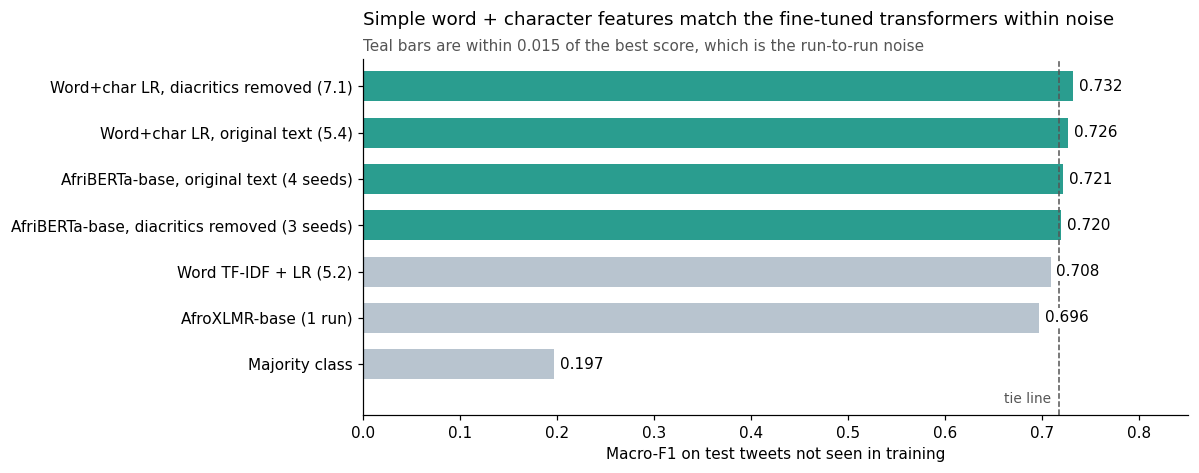

Problem,What we tried,Result,Decision
Tone marks and underdots,Removed them before the model sees the text,"Overall score unchanged (0.726 to 0.732 linear, 0.721 to 0.720 AfriBERTa). Tweets written without tone marks improved by +0.044 and +0.048",Adopted
Negation,Tagged the words inside a negation's scope,No gain. Models still over-predict negative on negated tweets,"Rejected, kept as a known weakness"
Code-mixing with English,"Compared the models on code-mixed tweets, then tried routing them to AfroXLMR",Penalty and advantage did not hold across validation and test. Routing changed the score by -0.002 to +0.009,Not deployed
Training data size,Retrained the linear model on growing fractions of the data,About +0.03 macro-F1 for every doubling of the data,More data is the clearest way forward


In [30]:
# [4] Model comparison with noise band, and the three problems tested
comp = pd.read_csv(f"{CKPT_DIR}/final_comparison.csv")
name_col = comp.columns[0]
score_col = "test_unseen macro-F1"
comp = comp.sort_values(score_col).reset_index(drop=True)
best = comp[score_col].max()

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = ["#2a9d8f" if s >= best - 0.015 else "#b8c4cf" for s in comp[score_col]]
ax.barh(comp[name_col], comp[score_col], color=colors, height=0.65)
for i, s in enumerate(comp[score_col]):
        ax.text(s + 0.006, i, f"{s:.3f}", va="center", fontsize=10, zorder=5,
            bbox=dict(fc="white", ec="none", pad=1.5))
ax.axvline(best - 0.015, color="#555", ls="--", lw=1)
ax.text(best - 0.015 - 0.008, -0.75, "tie line", ha="right", va="center", fontsize=9, color="#555")
ax.set_xlim(0, 0.85)
ax.set_ylim(-1.1, len(comp) - 0.4)
ax.set_xlabel("Macro-F1 on test tweets not seen in training")
ax.set_title("Simple word + character features match the fine-tuned transformers within noise", loc="left", pad=22)
ax.text(0, 1.02, "Teal bars are within 0.015 of the best score, which is the run-to-run noise", transform=ax.transAxes,
        fontsize=10, color="#555")
plt.tight_layout()
plt.show()

problems = pd.DataFrame([
    ["Tone marks and underdots",
     "Removed them before the model sees the text",
     "Overall score unchanged (0.726 to 0.732 linear, 0.721 to 0.720 AfriBERTa). Tweets written without tone marks improved by +0.044 and +0.048",
     "Adopted"],
    ["Negation",
     "Tagged the words inside a negation's scope",
     "No gain. Models still over-predict negative on negated tweets",
     "Rejected, kept as a known weakness"],
    ["Code-mixing with English",
     "Compared the models on code-mixed tweets, then tried routing them to AfroXLMR",
     "Penalty and advantage did not hold across validation and test. Routing changed the score by -0.002 to +0.009",
     "Not deployed"],
    ["Training data size",
     "Retrained the linear model on growing fractions of the data",
     "About +0.03 macro-F1 for every doubling of the data",
     "More data is the clearest way forward"],
], columns=["Problem", "What we tried", "Result", "Decision"])
display(problems.style.hide(axis="index").set_properties(**{"text-align": "left"}))

## 5. Evaluation of the deployed model

Check: macro-F1 0.732, accuracy 0.746, errors 1,001


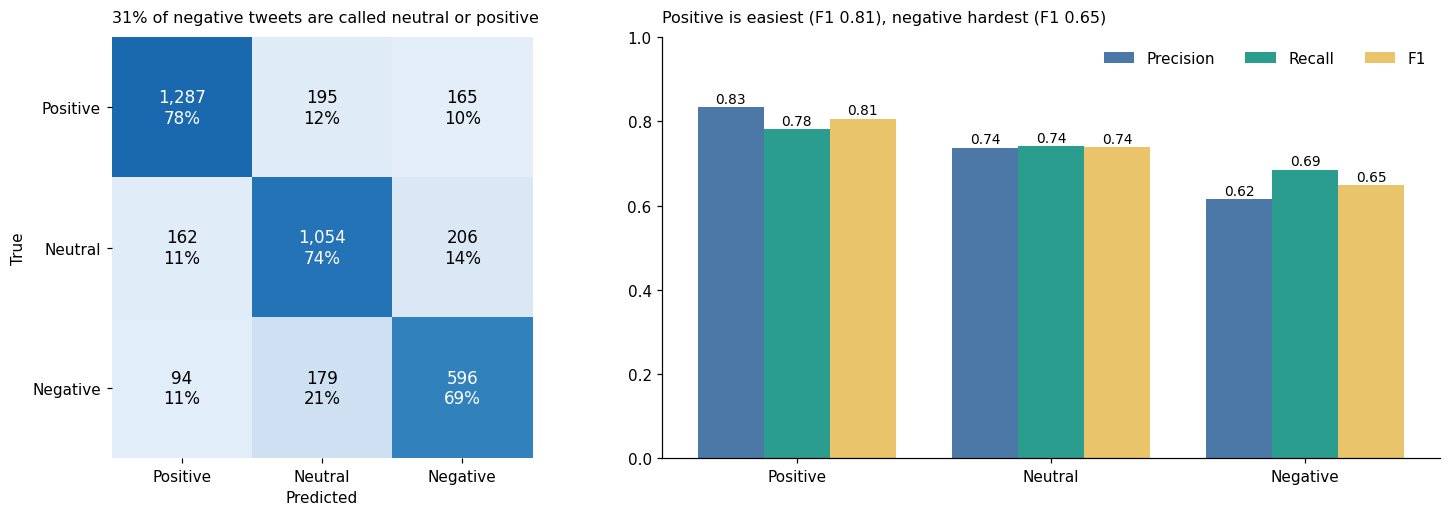

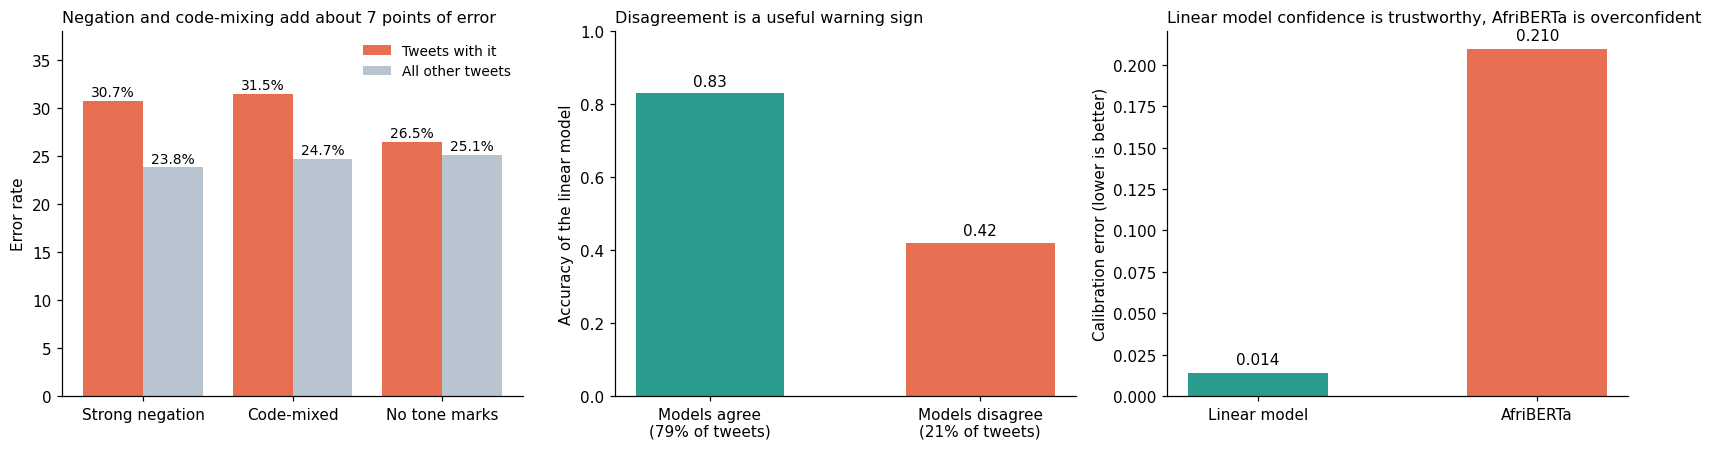

In [32]:
# [5] Evaluation of the deployed word + character model on 3,938 unseen test tweets
# Values below are copied from the error-analysis results in the report (that notebook was not rerun)
labels = ["Positive", "Neutral", "Negative"]
cm = np.array([[1287, 195, 165],
               [162, 1054, 206],
               [94, 179, 596]])
error_rates = {"Strong negation": (30.7, 23.8), "Code-mixed": (31.5, 24.7), "No tone marks": (26.5, 25.1)}
agree_share, agree_acc, disagree_acc = 79.3, 0.830, 0.42
ece = {"Linear model": 0.014, "AfriBERTa": 0.210}

tp = np.diag(cm)
precision = tp / cm.sum(axis=0)
recall = tp / cm.sum(axis=1)
f1 = 2 * precision * recall / (precision + recall)
print(f"Check: macro-F1 {f1.mean():.3f}, accuracy {tp.sum() / cm.sum():.3f}, errors {cm.sum() - tp.sum():,}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
rowpct = cm / cm.sum(axis=1, keepdims=True)
ax1.imshow(rowpct, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax1.text(j, i, f"{cm[i, j]:,}\n{rowpct[i, j]:.0%}", ha="center", va="center", fontsize=11,
                 color="white" if rowpct[i, j] > 0.5 else "black")
ax1.set_xticks(range(3)); ax1.set_xticklabels(labels); ax1.set_yticks(range(3)); ax1.set_yticklabels(labels)
ax1.set_xlabel("Predicted"); ax1.set_ylabel("True")
ax1.set_title("31% of negative tweets are called neutral or positive", loc="left", fontsize=10.5, pad=10)
ax1.spines[:].set_visible(False)

x = np.arange(3); w = 0.26
for k, (vals, name, c) in enumerate([(precision, "Precision", "#4c78a8"), (recall, "Recall", "#2a9d8f"), (f1, "F1", "#e9c46a")]):
    bars = ax2.bar(x + (k - 1) * w, vals, w, label=name, color=c)
    for b, v in zip(bars, vals):
        ax2.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax2.set_xticks(x); ax2.set_xticklabels(labels); ax2.set_ylim(0, 1)
ax2.set_title("Positive is easiest (F1 0.81), negative hardest (F1 0.65)", loc="left", fontsize=10.5, pad=10)
ax2.legend(frameon=False, ncol=3, loc="upper right", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

fig, (ax3, ax4, ax5) = plt.subplots(1, 3, figsize=(15, 4.2))
names = list(error_rates)
with_f = [error_rates[n][0] for n in names]; without_f = [error_rates[n][1] for n in names]
xx = np.arange(len(names))
ax3.bar(xx - 0.2, with_f, 0.4, color="#e76f51", label="Tweets with it")
ax3.bar(xx + 0.2, without_f, 0.4, color="#b8c4cf", label="All other tweets")
for i, (a, b) in enumerate(zip(with_f, without_f)):
    ax3.text(i - 0.2, a + 0.5, f"{a:.1f}%", ha="center", fontsize=9); ax3.text(i + 0.2, b + 0.5, f"{b:.1f}%", ha="center", fontsize=9)
ax3.set_xticks(xx); ax3.set_xticklabels(names); ax3.set_ylim(0, 38); ax3.set_ylabel("Error rate")
ax3.set_title("Negation and code-mixing add about 7 points of error", loc="left", fontsize=10.5)
ax3.legend(frameon=False, loc="upper right", fontsize=9)

ax4.bar(["Models agree\n(79% of tweets)", "Models disagree\n(21% of tweets)"], [agree_acc, disagree_acc], color=["#2a9d8f", "#e76f51"], width=0.55)
for i, v in enumerate([agree_acc, disagree_acc]):
    ax4.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)
ax4.set_ylim(0, 1); ax4.set_ylabel("Accuracy of the linear model")
ax4.set_title("Disagreement is a useful warning sign", loc="left", fontsize=10.5)

ax5.bar(list(ece), list(ece.values()), color=["#2a9d8f", "#e76f51"], width=0.5)
for i, v in enumerate(ece.values()):
    ax5.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=10)
ax5.set_ylabel("Calibration error (lower is better)")
ax5.set_title("Linear model confidence is trustworthy, AfriBERTa is overconfident", loc="left", fontsize=10.5)
plt.tight_layout()
plt.show()

## 6. Examples from the test set

In [39]:
# [6] One example of each kind of outcome, from tweets the model has not seen
MODEL_REPO = "Thevyne/yoruba-sentiment-models"
lr_file = next(f for f in list_repo_files(MODEL_REPO) if f.endswith(".joblib"))
lr_model = joblib.load(hf_hub_download(MODEL_REPO, lr_file))

def strip_marks(text):
    d = unicodedata.normalize("NFD", text)
    return unicodedata.normalize("NFC", "".join(c for c in d if not unicodedata.combining(c)))

names = {0: "positive", 1: "neutral", 2: "negative"}
flags = pd.read_parquet(f"{CKPT_DIR}/step4_flags_test.parquet")
unseen = flags[~flags["seen_in_training"]].reset_index(drop=True)
src = "text_aligned" if "text_aligned" in unseen.columns else "tweet"
pred = lr_model.predict([strip_marks(t) for t in unseen[src]])
unseen["True"] = unseen["label"].map(names)
unseen["Prediction"] = pd.Series(pred).map(names)
print(f"Check: macro-F1 on {len(unseen):,} unseen tweets = {f1_score(unseen['label'], pred, average='macro'):.3f}")

readable = unseen[unseen["tweet"].str.len().between(40, 140)]
picks = []
for c in names.values():
    picks.append(readable[(readable["True"] == c) & (readable["Prediction"] == c)].sample(1, random_state=11).assign(Group="Right"))
for t in names.values():
    for p in names.values():
        if t != p:
            picks.append(readable[(readable["True"] == t) & (readable["Prediction"] == p)].sample(1, random_state=23).assign(Group="Wrong"))
ex = pd.concat(picks).reset_index(drop=True)
ex["Tweet"] = ex["tweet"].str.replace(r"\s+", " ", regex=True)

def paint(table):
    def colour(col):
        return ["background-color:#d8f0e6" if v == t else "background-color:#f8dcd6" for v, t in zip(col, table["True"])]
    return (table.style.hide(axis="index").set_properties(**{"text-align": "left"}).apply(colour, subset=["Prediction"]))

cols = ["Tweet", "True", "Prediction"]
display(Markdown("**Tweets the model gets right**")); display(paint(ex[ex["Group"] == "Right"][cols]))
display(Markdown("**One example of each kind of mistake**")); display(paint(ex[ex["Group"] == "Wrong"][cols]))

Check: macro-F1 on 3,938 unseen tweets = 0.732


**Tweets the model gets right**

Tweet,True,Prediction
ọ̀yẹ̀là bí iná bá wọlé òkùnkùn a sì paradà ẹ káàárọ̀ o ẹ̀yin olólùfpẹ́ẹ tèmi nìkan,positive,positive
ẹ gbọ́ o dòdò ni kí n fi ọ̀gẹ̀dẹ̀ yí ṣe ni àbí bọ̀ọ̀lì,neutral,neutral
ìyà ń bẹ fún ọmọ tí ò gbọ́n ẹkún ń bẹ fún ọmọ tó ń sá kiri,negative,negative


**One example of each kind of mistake**

Tweet,True,Prediction
a ò ní fọwọ́ tẹ ìgànná kátó wọ ìyẹ̀wù sùn o,positive,neutral
eyin orekelewa omoge ile kaaro ojire to mo faajie kan si arabinrin lati ra sokoto igbalode ti won pe ni pallazo,positive,negative
ìrèní ọjọ́ mẹ́ta òní ìfàní ìdúnta ọdún mẹ́ta sẹ́yìn ìdúnsànán,neutral,positive
awon osise worldbank so wipe kankan ti ilo ayarabiasa ba lo soke ni ilu wa a mu idagba ni gdp na lo so,neutral,negative
a ma ń ṣe bí ẹni mọ ìyá ọ̀ṣọ́ ju ọ̀ṣọ́ lọ ♬ we act more catholic than the pope,negative,positive
oro apoda ni un so igba ti fi enu warofu nibo lo wa lo ka ofin cybercrimes prohibition prevention etc act,negative,neutral


## 7. Live demo

## 7. Live demo

[Open the app on Hugging Face](https://huggingface.co/spaces/Thevyne/yoruba-sentiment)

## 8. Limitations

In [40]:
# [8] Limitations, with the evidence for each
limits = pd.DataFrame([
    ["Negation", "Error rate 30.7% on strongly negated tweets against 23.8% on the rest. Scope tagging did not fix it", "A model or features that handle negation scope"],
    ["Code-mixing with English", "Error rate 31.5% against 24.7%. The gap was not stable across validation and test", "More code-mixed training data"],
    ["Overlap between splits", "12.8% of test tweets also appear in training, so scores are reported on unseen tweets only", "De-duplicated splits from the start"],
    ["Transformer comparison", "AfroXLMR has one reported run. Differences under 0.015 between models are a tie", "More seeds per model"],
    ["Label checking", "The planned human review of errors was not completed, so no agreement score is reported", "A second Yoruba reader on a sample of errors"],
    ["Amount of data", "Score rises about 0.03 for every doubling of training data", "More labelled Yoruba tweets"],
], columns=["Limitation", "Evidence", "What would help"])
display(limits.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Limitation,Evidence,What would help
Negation,Error rate 30.7% on strongly negated tweets against 23.8% on the rest. Scope tagging did not fix it,A model or features that handle negation scope
Code-mixing with English,Error rate 31.5% against 24.7%. The gap was not stable across validation and test,More code-mixed training data
Overlap between splits,"12.8% of test tweets also appear in training, so scores are reported on unseen tweets only",De-duplicated splits from the start
Transformer comparison,AfroXLMR has one reported run. Differences under 0.015 between models are a tie,More seeds per model
Label checking,"The planned human review of errors was not completed, so no agreement score is reported",A second Yoruba reader on a sample of errors
Amount of data,Score rises about 0.03 for every doubling of training data,More labelled Yoruba tweets
